# 08 · Final evaluation and analysis
The held-out test period was opened **once** by `python run_all.py`, after the design was frozen (`results/models/frozen_design.sha256`); see the access log at the bottom.
Nothing below changes a feature, model, hyper-parameter, preprocessing step or hypothesis. Residual-based statements describe the errors; they are not read as evidence that the model is good.
**Code.** `Experiment.stage_final_test`, `stage_analysis`, `stage_report`; `src/evaluation.py`.

In [1]:
import io, json, re, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
from src import config as C

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)

def table(stem, **kw):
    """results/tables/<stem>.csv (written by run_all.py)."""
    return pd.read_csv(C.TABLES / f"{stem}.csv", **kw)

def caption(stem):
    txt = (C.FIGURES / "figure_captions.md").read_text()
    m = re.search(rf"\*\*{re.escape(stem)}\*\* - (.*?)(?:\n\n|\Z)", txt, re.S)
    return m.group(1).strip() if m else ""

def fig(stem, width=1500):
    """Show results/figures/<stem>.png (down-scaled to keep the notebook small) with the caption computed from the data."""
    im = PILImage.open(C.FIGURES / f"{stem}.png")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue())); display(Markdown(f"*{caption(stem)}*"))

def log_grep(pattern, maxlen=420):
    """Print the lines of results/logs/run_all.log that match a regular expression."""
    for line in (C.LOGS / "run_all.log").read_text().splitlines():
        if re.search(pattern, line):
            print(line[:maxlen])

## 1. Summary printed at the end of `run_all.py`

In [2]:
print((C.RESULTS / "final_summary.txt").read_text())

DATASET
Rows: 35,064 (file) -> 35,063 after target construction
Features: 54 design columns in the final Set C (from 37 candidate columns); Set A: 26
Time range: 2013-03-01 00:00 to 2017-02-28 23:00
Sampling interval: 1 hour (regular, 0 missing timestamps)
Station: Aotizhongxin
Target: PM2.5 concentration at t+1 hour
Target unit: ug/m3

TASK
Prediction: X(t) -> PM2.5(t+1)
Allowed at hour t: current pollutants and meteorology, calendar of t, PM2.5 up to t (current value, lags, rolling statistics of the shifted series).
Forbidden: PM2.5(t+1) or any later value, future meteorology, centred rolling windows, any statistic fitted on test data.

SPLIT
Train: 28,050 hours 2013-03-01 00:00 -> 2016-05-12 17:00 (26,000 usable)
Test:  7,013 hours 2016-05-12 18:00 -> 2017-02-28 22:00 (6,752 usable)

HYPOTHESES (pre-registered; verdict from training CV + training inference)
H1: Supported - Recent PM2.5 predicts next-hour PM2.5 (C vs C - PM2.5 history: dMAE +96.96 %, worse in 5/5 folds; joint Wald p 

## 2. Main results (Table 3; best value per column in bold)

Method,CV_MAE,CV_MAE_std,CV_RMSE,CV_RMSE_std,Test_MAE,Test_RMSE,Test_R2
Training mean,62.46,11.29,82.25,19.15,61.93,84.66,-0.0010
Persistence: PM2.5(t+1) = PM2.5(t),10.69,1.40,20.23,3.16,10.36,19.28,0.9481
Single-feature OLS: PM2.5(t) -> PM2.5(t+1),10.91,1.51,20.10,3.15,10.47,19.16,0.9487
Random Forest (raw features),11.14,1.96,21.14,5.03,10.20,18.86,0.9503
Gradient Boosting (raw features),11.76,2.64,22.18,6.23,10.27,18.88,0.9502
"OLS (linear, Set C)",10.62,1.35,18.90,2.77,10.05,17.75,0.9560
"Ridge (linear, Set C)",10.62,1.35,18.90,2.77,10.05,17.75,0.9560
"Lasso ★ (linear, Set C)",10.51,1.29,19.00,2.93,10.06,18.00,0.9547
"Elastic Net (linear, Set C)",10.62,1.35,18.90,2.77,10.05,17.75,0.9560


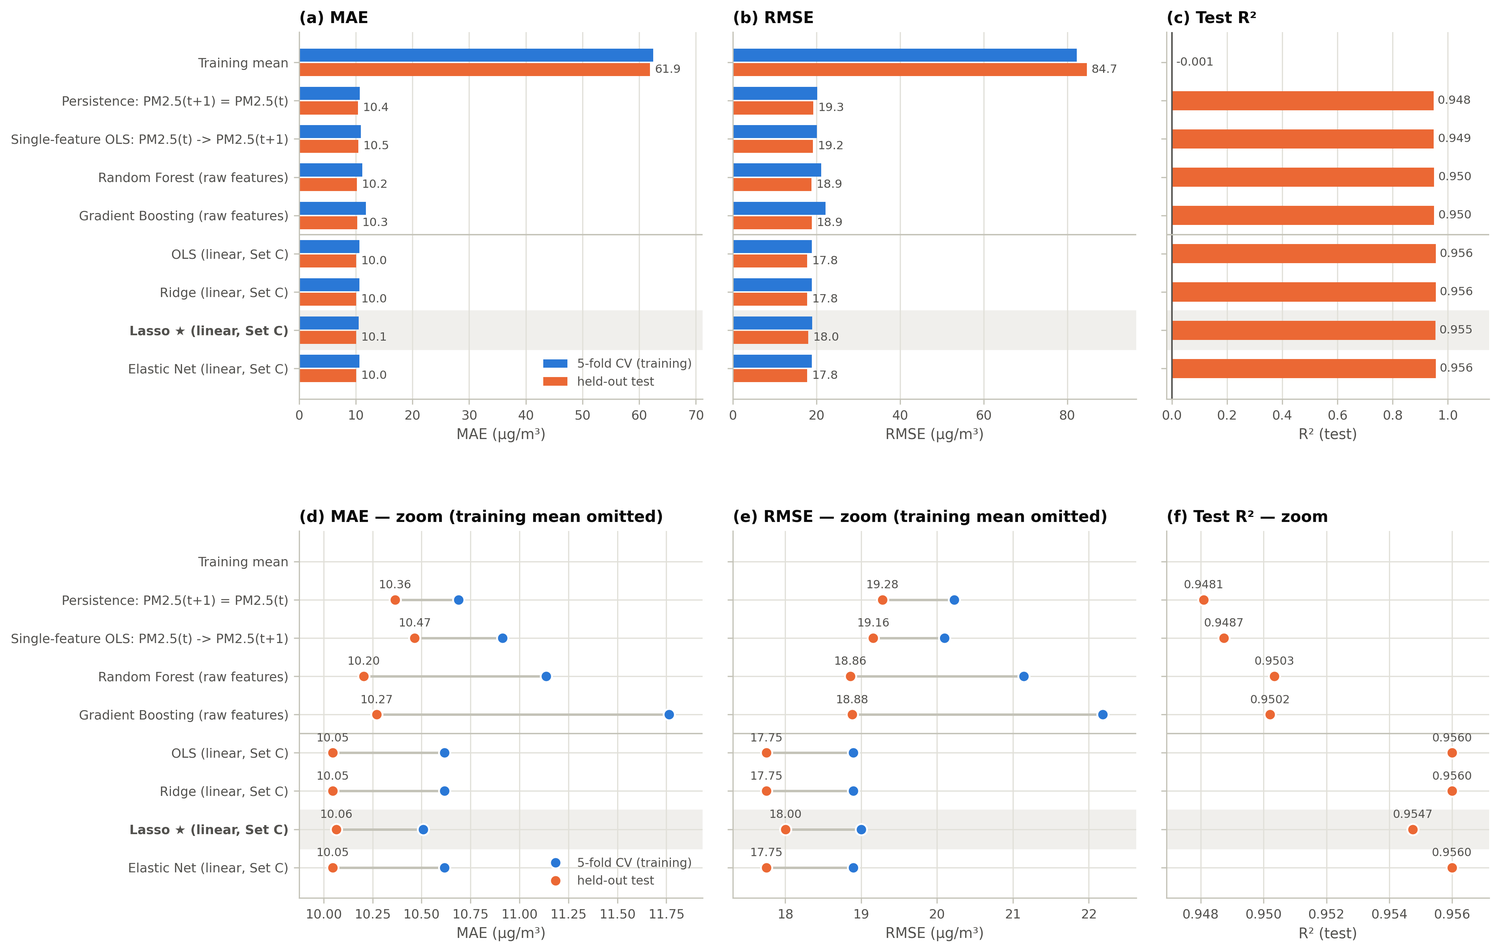

*Baselines and linear models (linear models on Set C): mean 5-fold time-series CV error on the training rows (blue) and one evaluation on the held-out test period (orange); ★ and the grey band mark the selected final model (Lasso). Top row: full scale (the training mean, test MAE 61.9, dominates the axis); bottom row: zoom without the training mean. Test MAE: persistence 10.36, single-feature OLS 10.47, Random Forest 10.20, Gradient Boosting 10.27; the four linear families 10.05-10.06 (final model 10.06, -2.9 % vs persistence; Diebold-Mariano p = 4.4e-05). Test R² is 0.955-0.956 for the linear families and 0.948 for persistence. CV and test errors cover different periods and are not directly comparable; the fold-to-fold standard deviation of the final model's CV MAE is ±1.29.*

,final model vs,Δ squared error,DM p (squared error),Δ absolute error,DM p (absolute error),better under RMSE,better under MAE
0,Training mean,-6844.014742,3.721255e-14,-51.863631,8.048237e-88,final,final
1,Persistence,-47.638525,4.571690e-12,-0.299191,4.424565e-05,final,final
2,Single-feature OLS,-43.063640,7.858442e-15,-0.400007,9.466927e-10,final,final
3,Random Forest (raw),-31.519911,5.306294e-04,-0.139459,1.138266e-01,final,final
4,Gradient Boosting (raw),-32.503302,1.725279e-02,-0.206546,6.049537e-02,final,final
5,"Random Forest (Set C, reference)",17.691512,5.268619e-05,0.530318,2.733229e-17,comparator,comparator
6,"Gradient Boosting (Set C, reference)",2.261026,8.724794e-01,0.355095,5.265750e-04,comparator,comparator
7,"Linear, Set A (raw)",-33.562314,6.370538e-15,-0.336631,1.512716e-08,final,final
8,"Linear, Set B",-33.802571,1.883628e-14,-0.321329,5.714356e-08,final,final
9,"Linear, Set B′",-2.517951,5.303686e-01,0.059733,2.288995e-01,final,comparator


In [3]:
t3 = table("table_3_model_comparison")
show = t3[["Method", "CV_MAE", "CV_MAE_std", "CV_RMSE", "CV_RMSE_std", "Test_MAE", "Test_RMSE", "Test_R2"]].copy()
fmt = {c: "{:.2f}" for c in show.columns[1:7]}; fmt["Test_R2"] = "{:.4f}"
display(show.style.format(fmt).hide(axis="index")
        .highlight_min(subset=["CV_MAE", "CV_RMSE", "Test_MAE", "Test_RMSE"], props="font-weight: bold; background-color: #cde2fb")
        .highlight_max(subset=["Test_R2"], props="font-weight: bold; background-color: #cde2fb"))
fig("figure_07_model_comparison")
display(table("table_S11_diebold_mariano"))

## 3. Decision threshold
`DECISION_THRESHOLD` (`src/config.py`) is a **proposed** operational tolerance in µg/m³, not an authoritative standard; the sensitivity table shows how the comparison depends on it.

DECISION_THRESHOLD = 10.0 µg/m³ (proposed; to be confirmed or overridden by the author)


,model,within 5,within 10,within 15,within 20,within 35
0,final model (Set C),0.438,0.700,0.823,0.887,0.954
1,"linear, Set A",0.450,0.696,0.812,0.877,0.948
2,persistence,0.493,0.711,0.822,0.884,0.948
3,training mean,0.042,0.089,0.140,0.181,0.312


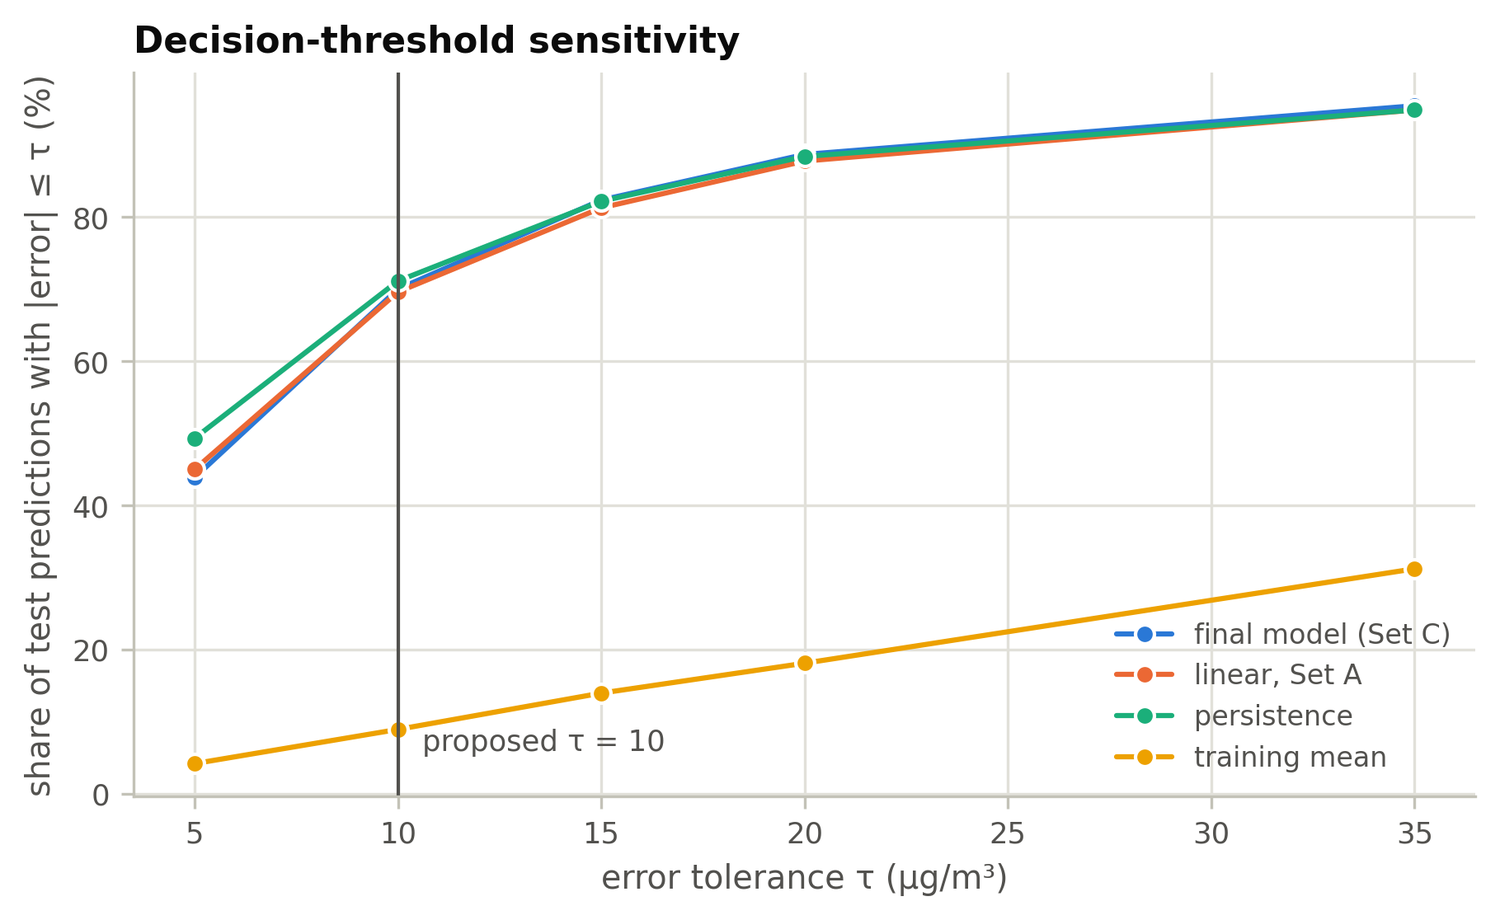

*Share of test predictions whose absolute error is at most τ, for several tolerances τ (µg/m³). At the proposed τ = 10 µg/m³ the final model is within tolerance in 70.0 % of the hours (linear Set A 69.6 %, persistence 71.1 %, training mean 8.9 %). The tolerance is a configurable, non-authoritative operating choice: the proposed default is marked and the curves show how the comparison depends on it.*

In [4]:
print("DECISION_THRESHOLD =", C.DECISION_THRESHOLD, "µg/m³ (proposed; to be confirmed or overridden by the author)")
display(table("table_S12_decision_threshold_sensitivity").round(3))
fig("figure_S07_decision_threshold_sensitivity")

## 4. Slice-level performance (final test predictions; cut-offs from the training data or the calendar)

,Slice group,Slice,n,Final MAE,Final RMSE,Set A MAE,Set A RMSE,Persistence MAE,Persistence RMSE,Δ MAE vs Set A,Δ MAE vs persistence,bias (final)
0,PM2.5 level (actual),low (<= P25 = 23),1920,5.47,10.30,5.26,10.74,4.78,10.72,0.20,0.68,-1.77
1,PM2.5 level (actual),mid (P25-P75),3281,8.87,14.28,9.24,15.32,9.70,16.03,-0.37,-0.83,-0.31
2,PM2.5 level (actual),high (>= P75 = 116),1551,18.29,29.12,19.21,30.29,18.69,30.53,-0.93,-0.40,6.72
3,PM2.5 level (actual),episode (>= P95 = 247),345,26.48,40.13,28.20,41.84,26.21,40.50,-1.72,0.27,13.63
4,Time of day (target hour),day (06-17 h),3364,9.75,17.02,10.13,17.97,10.24,18.53,-0.37,-0.49,0.49
5,Time of day (target hour),night,3388,10.38,18.92,10.68,19.80,10.49,19.99,-0.30,-0.11,1.29
6,Weekday / weekend,weekday,4758,9.74,17.15,10.07,18.03,10.04,18.41,-0.33,-0.30,0.84
7,Weekday / weekend,weekend,1994,10.84,19.89,11.20,20.86,11.13,21.22,-0.36,-0.29,1.02
8,Season,winter,2131,13.16,24.76,13.71,25.97,13.57,26.36,-0.55,-0.40,0.77
9,Season,spring,453,6.72,9.52,6.78,9.84,7.02,10.23,-0.06,-0.31,0.11


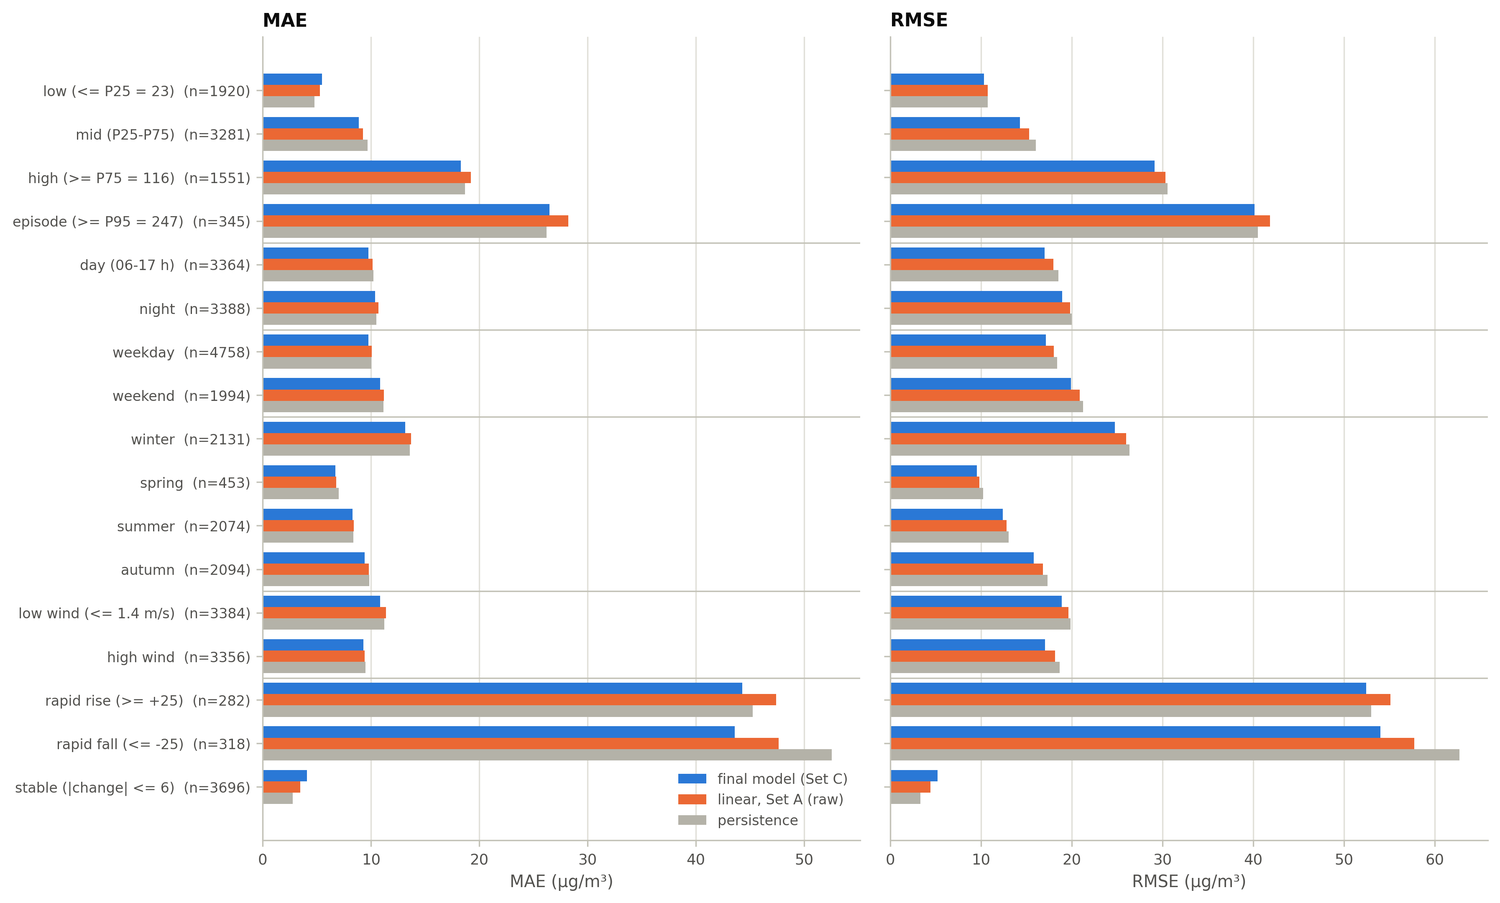

*Test-set MAE (left) and RMSE (right) of the final model (Set C), the same linear family on the raw features (Set A) and persistence, by slice (17 slices in 6 groups; slices of different groups overlap). Cut-offs come from the training data or the calendar. The PM2.5-level and one-hour-change slices are defined by the realised outcome: this favours persistence in stable hours and penalises every model in rapid-change hours, so they show where errors occur, not a condition known in advance. Largest final-model MAE: rapid rise (>= +25) (44.3); rapid fall (<= -25) (43.6); episode (>= P95 = 247) (26.5); smallest: stable (|change| <= 6) (4.1). The final model has a lower MAE than persistence in 14 of 17 slices and than Set A in 15; it is worse than persistence in: low (<= P25 = 23), episode (>= P95 = 247), stable (|change| <= 6).*

In [5]:
display(table("table_7_slice_level_performance").round(2))
fig("figure_12_slice_performance")

## 5. Error analysis: the three largest absolute errors

,case,time,actual,predicted,error,abs_error,hour,month,PM10,NO2,CO,TEMP,WSPM,wd,possible_explanation
0,1,2017-01-28 01:00:00,576.0,284.1,291.9,291.9,1,1,377.0,75.0,1600.0,-0.7,2.0,SE,"sudden pollution spike: PM2.5 jumped +271 ug/m3 within one hour (training 95th percentile of rises: +33); a linear model driven by the current level under-reacts to abrupt episodes; limited warning in the history: the jump (271) is 3.1x the 6-hour standard deviation (87) preceding it; wind-direction shift of 90 degrees (SW -> SE); extreme level (actual 576 >= training 99th percentile 366): few training examples, regression to the mean / extrapolation; external knowledge (not in the data): the target hour lies in the Chinese New Year fireworks window (first day 2017-01-28); fireworks are a documented short-lived PM2.5 source in Beijing, with peaks around 01:00-02:00 of the first day"
1,2,2016-12-22 03:00:00,149.0,396.0,-247.0,247.0,3,12,412.0,2.0,7700.0,0.3,0.4,ESE,"sudden clean-up: PM2.5 fell -263 ug/m3 within one hour (training 95th percentile of falls: -43); the forecast stays close to the previous high level; limited warning in the history: the jump (263) is 16.5x the 6-hour standard deviation (16) preceding it; the wind was calm (0.4 m/s, below the training median 1.4), so a ventilation-driven clean-up is not visible in the local wind data (possible local plume change or measurement artefact); PM10 equals PM2.5(t) exactly in this hour (a data-quality quirk present in 23 % of the training hours): the coarse-particle reading adds no independent information here"
2,3,2017-02-15 14:00:00,3.0,226.2,-223.2,223.2,14,2,229.0,97.0,2000.0,6.7,0.6,S,"sudden clean-up: PM2.5 fell -226 ug/m3 within one hour (training 95th percentile of falls: -43); the forecast stays close to the previous high level; limited warning in the history: the jump (226) is 16.9x the 6-hour standard deviation (13) preceding it; the wind was calm (0.6 m/s, below the training median 1.4), so a ventilation-driven clean-up is not visible in the local wind data (possible local plume change or measurement artefact); PM10 equals PM2.5(t) exactly in this hour (a data-quality quirk present in 23 % of the training hours): the coarse-particle reading adds no independent information here"


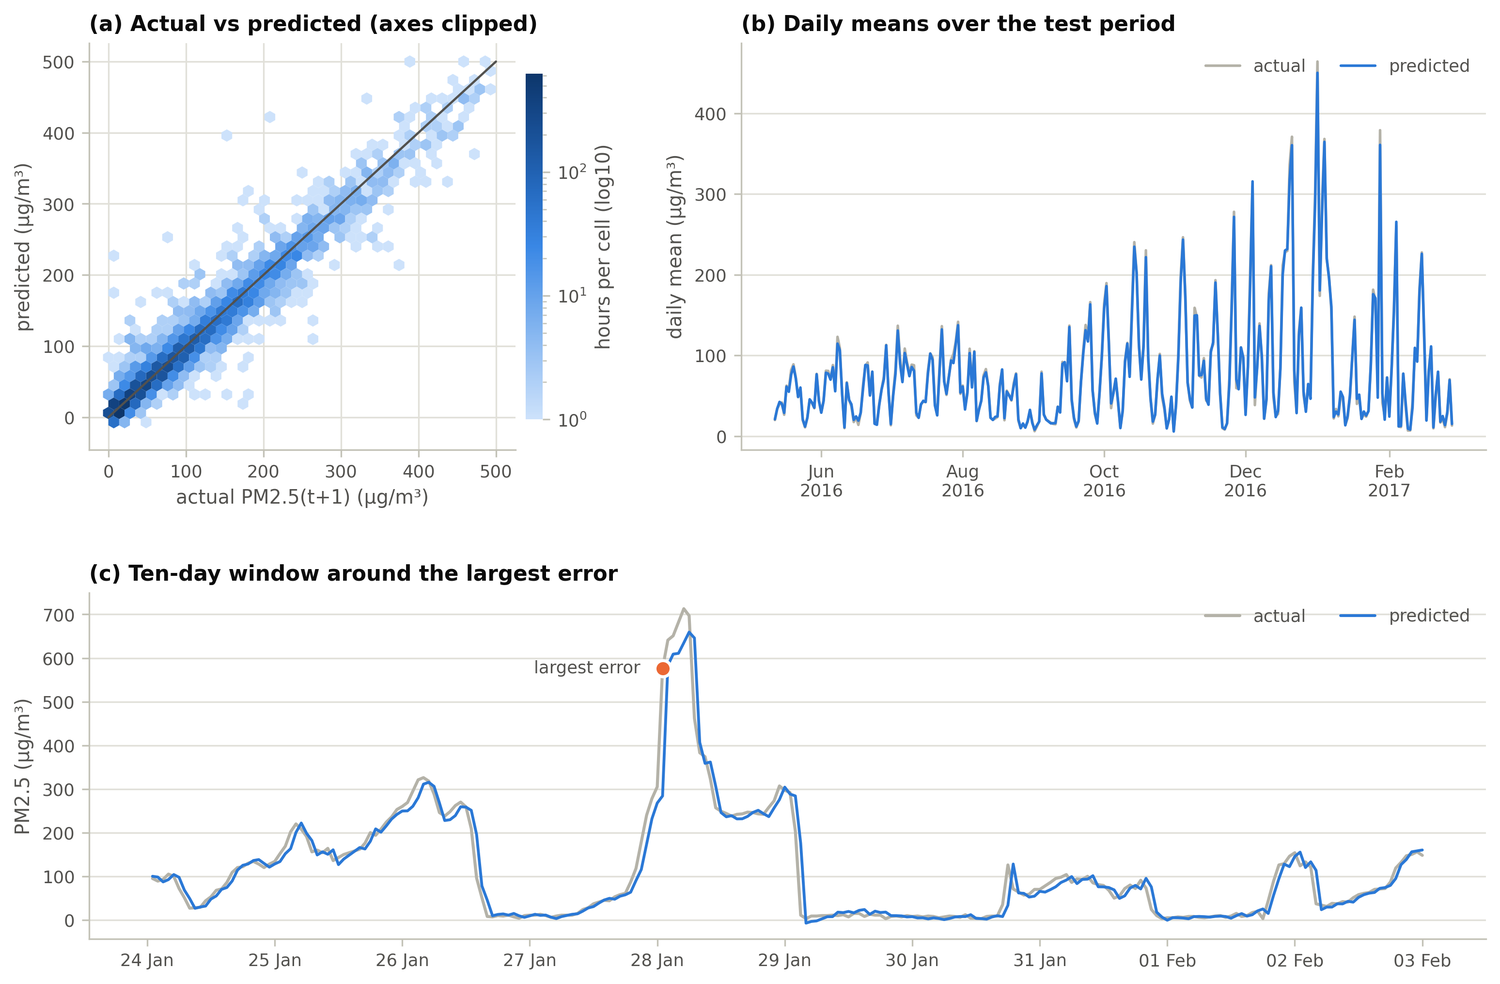

*Final model (Lasso, Set C) on the held-out test period (6,752 hours; MAE 10.06, R² 0.955). (a) Actual vs predicted hourly PM2.5 (axes clipped to 0-500 µg/m³; 0.3 % of the hours lie outside). (b) Daily means over the 291 test days (correlation 0.999). (c) Ten-day window around the largest absolute error (orange dot; target hour 2017-01-28 01:00, actual 576, predicted 284 µg/m³). The forecast follows the level closely but stays near the last observed value: it explains 13 % of the variance of the one-hour change PM2.5(t+1) - PM2.5(t) (linear Set A 4 %, persistence 0 % by construction), so abrupt rises and falls are reproduced about one hour late.*

one-hour change PM2.5(t+1) - PM2.5(t) in the test period: share of its variance explained - final model 12.8 %, linear Set A 3.8 %, persistence -0.0 % (<= 0 by construction)
  SHARED PATTERN: 1/3 are under-predictions; 1/3 follow a rapid one-hour rise (>= training P90 of |change|); 2 a rapid fall; |change| of the 3 cases = [271, 263, 226] = [8.2, 6.1, 5.3] x the training P95 of that direction; forecast minus PM2.5(t) = [-21, -16, -3]; among the largest 1 % of errors (68 hours): 41 % under-predictions, 100 % in rapid-change hours; they carry 43 % of the squared error
Among the largest 1 % of absolute errors (68 hours) 100 % occur in rapid-change hours (|change| >= training P90) and 41 % are under-predictions; these hours carry 43 % of the squared error. The final model explains 13 % of the variance of the one-hour change PM2.5(t+1) - PM2.5(t) (linear Set A 4 %, persistence 0 % by construction).


In [6]:
pd.set_option("display.max_colwidth", None)
display(table("table_6_three_largest_test_errors")[["case", "time", "actual", "predicted", "error", "abs_error", "hour", "month", "PM10", "NO2", "CO", "TEMP", "WSPM", "wd", "possible_explanation"]].round(1))
pd.set_option("display.max_colwidth", 90)
fig("figure_09_actual_vs_predicted")
log_grep(r"SHARED PATTERN|one-hour change PM2.5")

## 6. Residual analysis

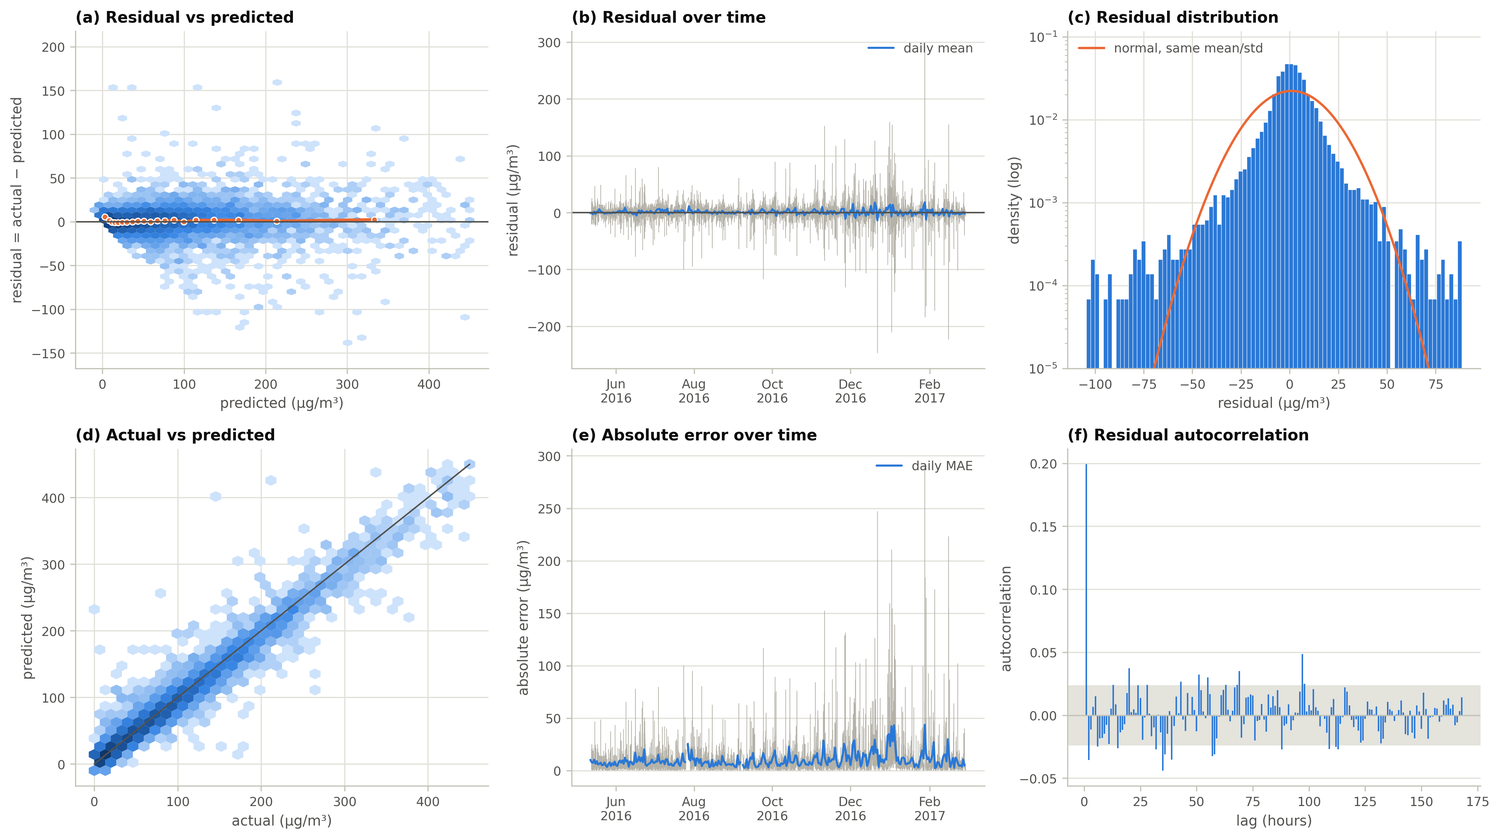

*Residual diagnostics of the final model on the test period (residual = actual - predicted). (a) The spread grows with the predicted level: the residual standard deviation in the highest prediction decile is 6.6 times that in the lowest (Breusch-Pagan p = 6.5e-72); orange: mean residual in 20 prediction bins. (b) Monthly mean residuals range from -0.5 to +2.3 µg/m³ (overall +0.89; 54 % of the hours under-predicted), but the swings grow in the pollution season: monthly MAE 6.7 (May 2016) to 15.1 (Dec 2016). (c) Residual distribution on a log density axis: skewness -0.62, excess kurtosis 36, far from normal (Jarque-Bera p < 1e-300); this describes the errors and is neither evidence for nor against the model. (d) Actual vs predicted. (e) Absolute error over time. (f) Residual autocorrelation (lag 1: +0.20, lag 24: +0.02; Durbin-Watson 1.60; Ljung-Box p = 1.1e-53 at lag 24; band: ±1.96/√n), so classical OLS standard errors would be too small - the inference tables use HAC errors and a block bootstrap.*

,diagnostic,value
0,Breusch-Pagan LM (residual^2 on prediction),3.215913e+02
1,Breusch-Pagan p,6.520530e-72
2,"Spearman(|resid|, prediction)",3.944961e-01
3,resid std top / bottom prediction decile,6.558239e+00
4,Durbin-Watson,1.597531e+00
5,residual ACF lag 1,1.992503e-01
6,residual ACF lag 2,-3.543498e-02
7,residual ACF lag 3,-1.133015e-02
8,residual ACF lag 6,-2.477797e-02
9,residual ACF lag 12,5.284775e-03


,n,pred_mean,resid_mean,resid_std,mae
0,676,5.52,3.52,5.69,4.85
1,675,13.27,-0.73,5.35,4.07
2,675,21.49,-0.85,9.54,5.68
3,675,33.34,-0.13,12.43,7.06
4,675,47.02,0.59,10.59,7.58
5,675,63.10,0.55,13.74,9.55
6,675,81.88,1.53,14.78,10.00
7,675,107.07,0.94,20.19,13.03
8,675,151.62,1.87,24.38,16.03
9,676,273.30,1.64,37.31,22.80


In [7]:
fig("figure_10_residual_analysis")
display(table("table_S13_residual_diagnostics"))
display(table("table_S14_residual_spread_by_prediction_decile").round(2))

## 7. Coefficient analysis (predictive model vs OLS statistical companion)
The final model is penalised, so ordinary OLS *p*-values do not exist for it. Intervals for the final model come from a moving-block bootstrap (one-week blocks); the **OLS companion** is fitted on the same
standardised Set C design with HAC (Newey–West) standard errors and supplies the *p*-values (Holm-adjusted) and VIFs. Training rows only.

,feature,group,coef,boot_lo,boot_hi,ols,hac_lo,hac_hi,p_hac,p_holm,vif
0,PM25_t,current PM2.5,79.737,70.013,87.684,85.835,81.806,89.865,0.000,0.000,25.059
1,PM25_lag_1,lag,-8.118,-11.992,-4.664,-18.079,-24.738,-11.420,0.000,0.000,130.342
2,WSPM_x_PM25,interaction,-3.288,-4.314,-2.049,-3.942,-5.085,-2.800,0.000,0.000,2.766
3,WSPM,meteorology / wind,-2.622,-3.360,-1.873,-3.048,-3.713,-2.384,0.000,0.000,2.401
4,DEWP_chg_3h,derived differences,2.541,2.054,2.999,2.212,1.698,2.726,0.000,0.000,1.354
5,PM10,pollutants,2.456,1.362,4.616,2.265,0.542,3.988,0.010,0.279,7.737
6,TEMP_minus_DEWP,derived differences,-2.177,-2.630,-1.622,-3.429,-3.981,-2.877,0.000,0.000,4.134
7,NO2,pollutants,1.759,1.043,2.434,1.977,1.336,2.618,0.000,0.000,3.646
8,hour_cos,temporal,-1.622,-1.961,-1.211,-1.846,-2.186,-1.507,0.000,0.000,1.548
9,hour_sin,temporal,-1.141,-1.561,-0.715,-1.091,-1.410,-0.772,0.000,0.000,1.775


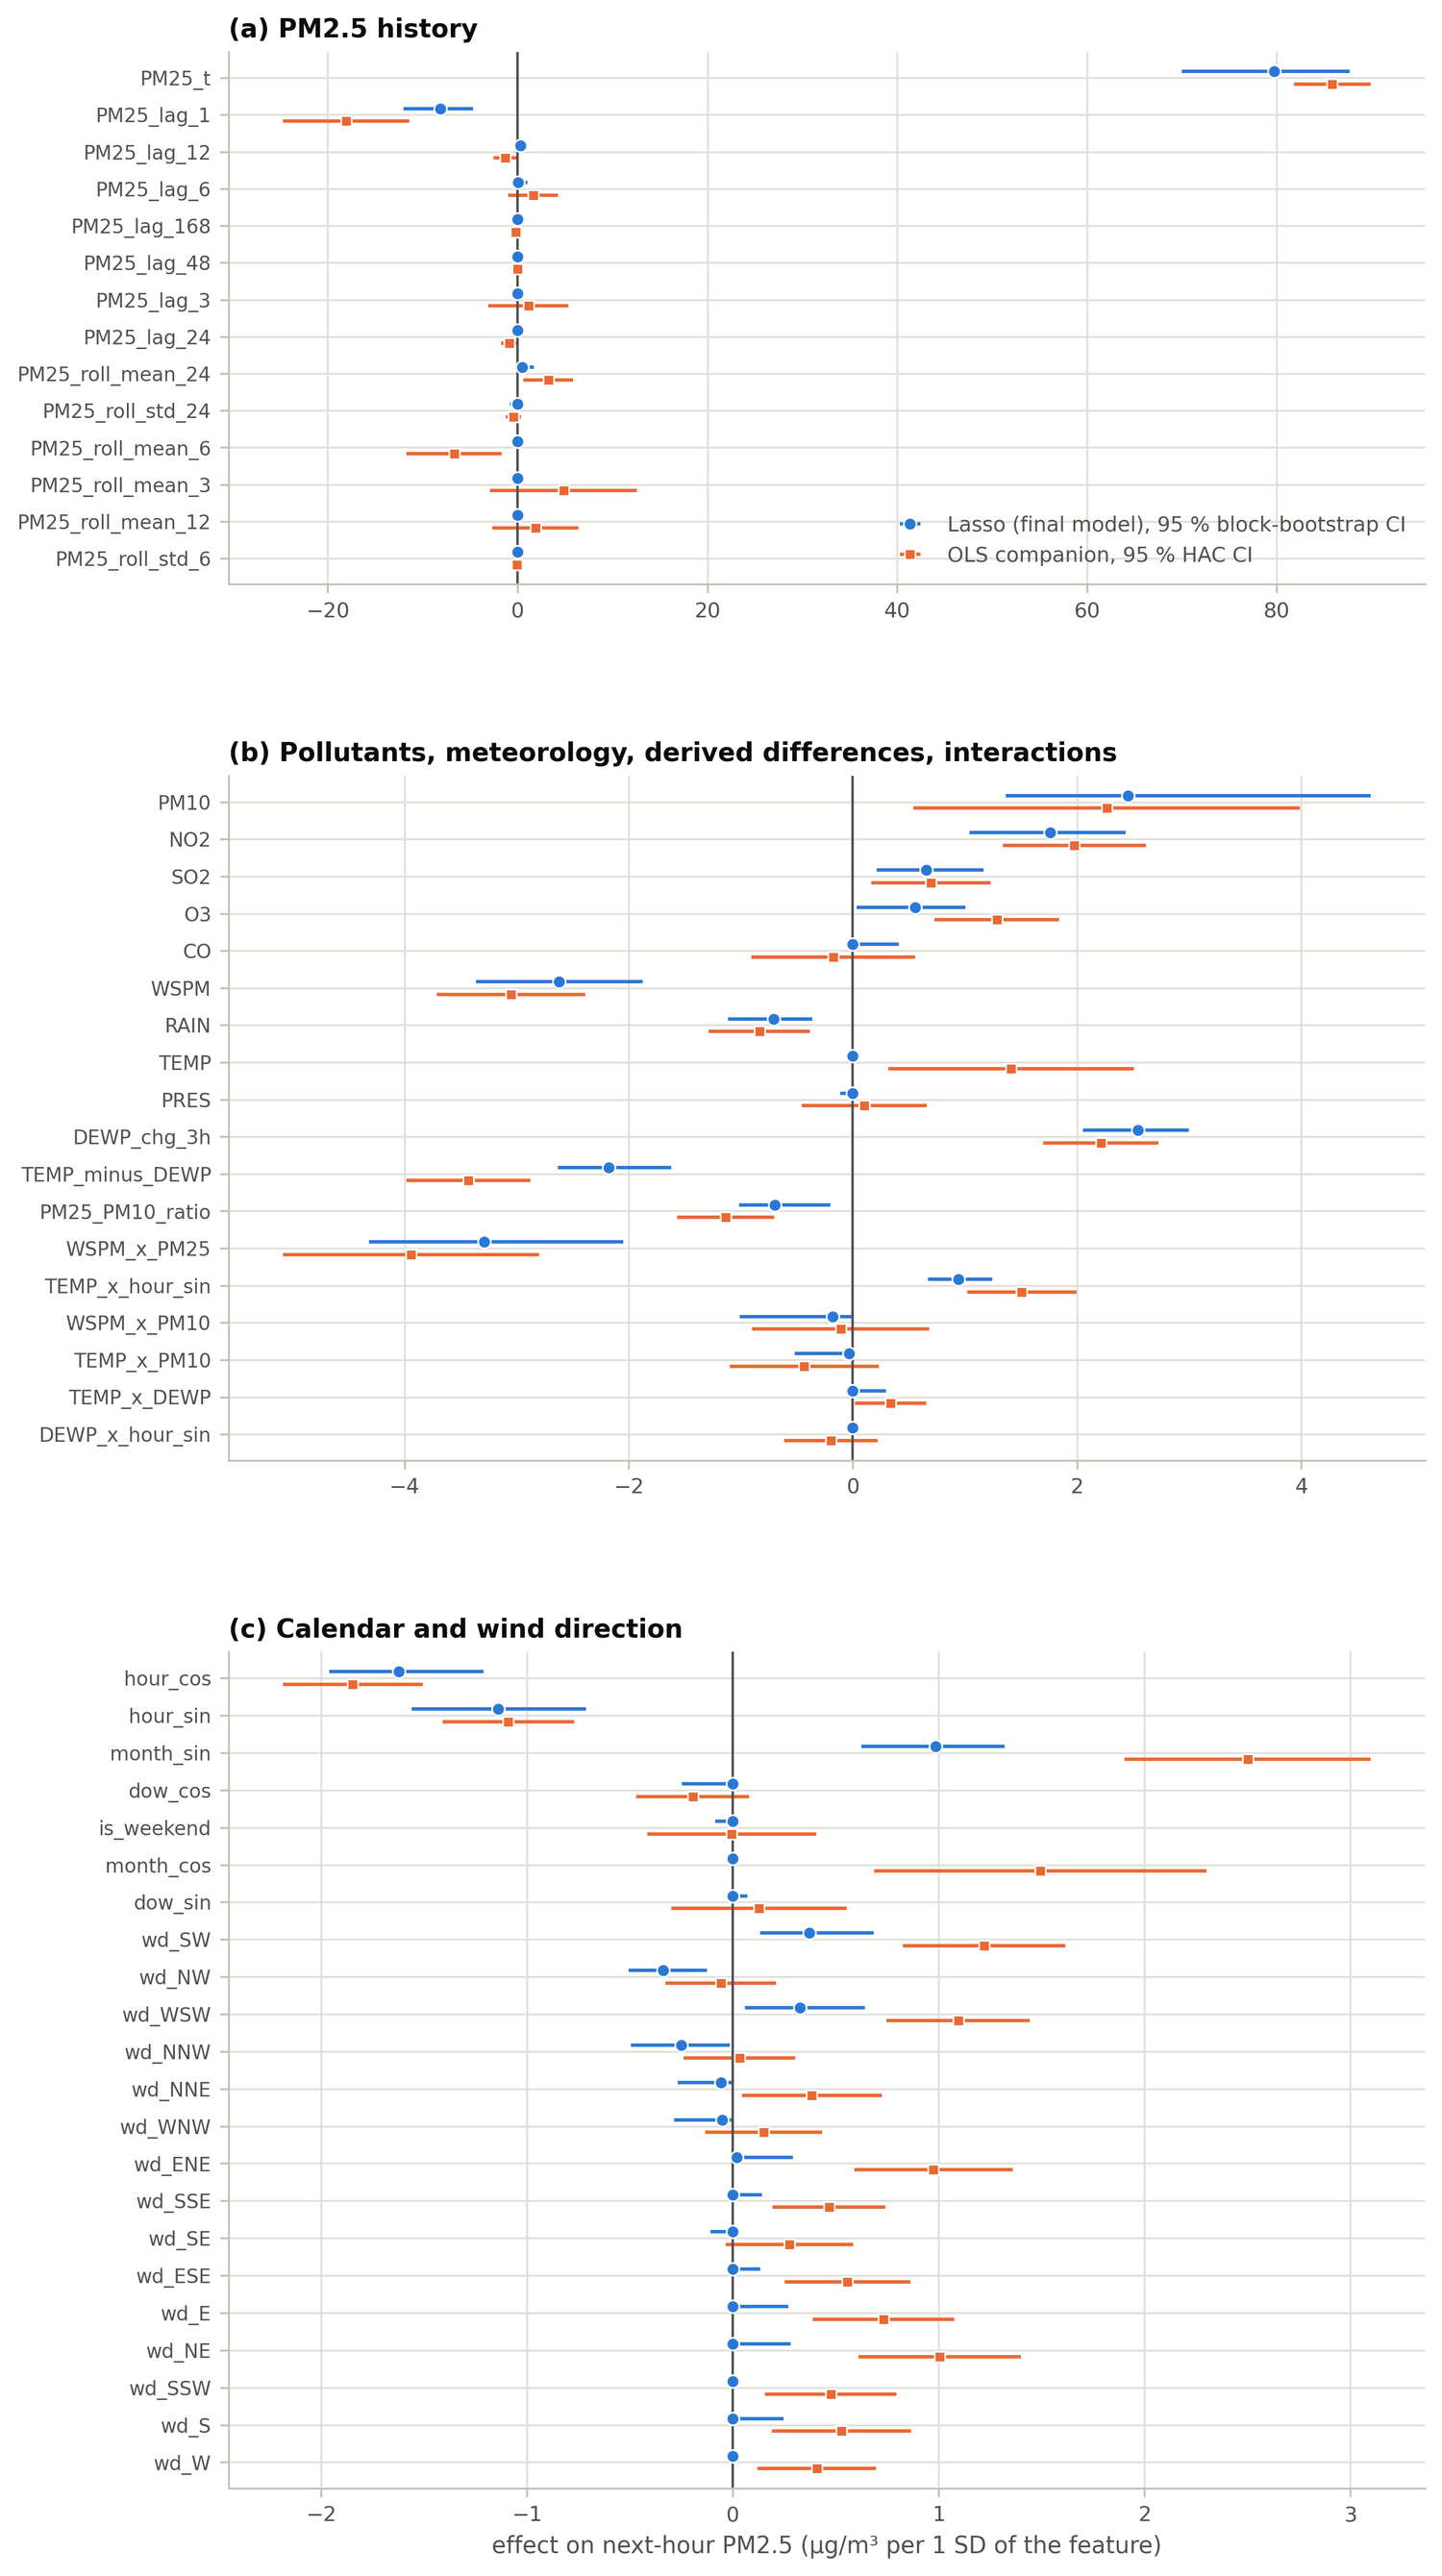

*Coefficients of the final model (Lasso, Set C) in µg/m³ of next-hour PM2.5 per one standard deviation of the (centred) feature, with 95 % intervals. Blue: penalised predictive model with moving-block-bootstrap intervals (one-week blocks); orange: OLS companion on the same standardised design with HAC (Newey-West) intervals. 29 of the 54 coefficients are non-zero; 20 bootstrap intervals exclude zero and 22 OLS-HAC p-values stay below 0.05 after Holm correction. Largest effects: PM25_t (+79.7), PM25_lag_1 (-8.1), WSPM_x_PM25 (-3.3). The three panels have different x-scales. The current PM2.5 and its first lag are strongly collinear (VIF 25 and 130) and have opposite signs, so they must be read together: the pair acts as the current level plus a fraction of the last one-hour change (momentum), not as two independent effects.*

,group,n_features,non_zero,sum_abs_coef,ci_excludes_zero,largest_effects
0,current PM2.5,1,1,79.74,1,PM25_t +79.74
1,lag,7,3,8.44,1,PM25_lag_1 -8.12; PM25_lag_12 +0.28; PM25_lag_6 +0.04
2,interaction,6,4,4.44,2,WSPM_x_PM25 -3.29; TEMP_x_hour_sin +0.94; WSPM_x_PM10 -0.18
3,meteorology / wind,19,9,4.74,6,WSPM -2.62; RAIN -0.71; wd_SW +0.37
4,derived differences,3,3,5.41,3,DEWP_chg_3h +2.54; TEMP_minus_DEWP -2.18; PM25_PM10_ratio -0.70
5,pollutants,5,4,5.42,4,PM10 +2.46; NO2 +1.76; SO2 +0.65
6,temporal,7,3,3.75,3,hour_cos -1.62; hour_sin -1.14; month_sin +0.98
7,rolling,6,2,0.52,0,PM25_roll_mean_24 +0.49; PM25_roll_std_24 -0.03


COEFFICIENT SIGNS READ AGAINST THE HYPOTHESES (final model, training coefficients, ug/m3 per SD; descriptive - the verdicts come from the pre-registered CV rule):
  H1 recent PM2.5: current PM25_t +79.74 | lags PM25_lag_1 -8.12, PM25_lag_6 +0.04, PM25_lag_12 +0.28 [3/7 non-zero] | rolling PM25_roll_mean_24 +0.49, PM25_roll_std_24 -0.03 [2/6 non-zero]
  H2 environment: pollutants PM10 +2.46, SO2 +0.65, NO2 +1.76, O3 +0.55 | meteorology RAIN -0.71, WSPM -2.62 | derived TEMP_minus_DEWP -2.18, DEWP_chg_3h +2.54, PM25_PM10_ratio -0.70 | interactions TEMP_x_PM10 -0.03, WSPM_x_PM10 -0.18, WSPM_x_PM25 -3.29, TEMP_x_hour_sin +0.94
  H3 calendar: hour_sin -1.14, hour_cos -1.62, month_sin +0.98 | joint Wald p (HAC): daily 8.7e-29, weekly 0.38, monthly 1.8e-18
  H4 rolling vs lag: 2/6 rolling and 3/7 lag coefficients are non-zero; removing all rolling features changes CV MAE by +0.01 %, removing all lags by +0.88 %


In [8]:
t5 = table("table_5_final_model_coefficients")
display(t5[["feature", "group", "coef", "boot_lo", "boot_hi", "ols", "hac_lo", "hac_hi", "p_hac", "p_holm", "vif"]].round(3))
fig("figure_11_coefficients_confidence_intervals")
display(table("table_S16_coefficients_by_group").round(2))
log_grep(r"^COEFFICIENT SIGNS|^  H[1-4] (recent|environment|calendar|rolling)")

## 8. Hypotheses revisited (training verdicts; test comparison for information only)

In [9]:
display(table("table_S17_hypothesis_verdicts").round(3))

,hypothesis,comparison,delta_cv_mae_pct,folds_worse,predictive,inferential_test,inferential,verdict,"test_delta_mae_pct (descriptive, not used for the verdict)"
0,H1,C vs C - PM2.5 history,96.958,5,True,joint Wald p < 1e-300,True,Supported,61.417
1,H2,C vs C - environment block,1.480,4,True,joint Wald p = 4e-115,True,Supported,0.055
2,H3,C vs C - calendar terms,0.490,2,False,joint Wald p = 8.2e-53,True,Partly supported,-0.477
3,H4,lag-only (C - rolling) relative to rolling-only (C - lag); negative = lag-only better,-0.860,0,False,"DM on out-of-fold |error| (rolling-only minus lag-only): mean +0.091, p = 1.6e-39",False,Not supported,-1.170


## 9. Access log of the held-out test period and the frozen design

In [10]:
display(pd.DataFrame(json.loads((C.LOGS / "test_access_log.json").read_text())))
print("frozen design sha256:", (C.MODELS / "frozen_design.sha256").read_text().strip())

,time_utc,reason,design_sha256,n_test_rows
0,2026-10-04T18:24:18+00:00,single evaluation of the frozen design,d34f696ca0598698871d0d9315ec72c8dac274a3bf16c826f2fa75ed8a118677,7013
1,2026-10-04T18:59:34+00:00,single evaluation of the frozen design,869857f9b4fa8a4d4bc63925bc109961c92311d10081f75d21a91ca8b48b4c21,7013
2,2026-10-04T19:10:23+00:00,single evaluation of the frozen design,869857f9b4fa8a4d4bc63925bc109961c92311d10081f75d21a91ca8b48b4c21,7013


frozen design sha256: 869857f9b4fa8a4d4bc63925bc109961c92311d10081f75d21a91ca8b48b4c21
